IMU_Sensor data analysis
This notebook is meant to analyse sensor data retrieved from an Adafruit imu 20948 ran through an ESP32-C6

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("../data")
FILE = DATA / "sample" / "still_flat.csv"
df = pd.read_csv(FILE)

In [2]:
df["t"] = (df["time_us"] - df["time_us"].iloc[0]) / 1e6
df.head()

,time_us,ax,ay,az,gx,gy,gz,t
0,102968,0.015,-0.025,1.004,0.69,0.34,0.07,0.000000
1,112613,0.019,-0.032,1.009,0.68,0.35,0.02,0.009645
2,122612,0.017,-0.026,1.009,0.59,0.53,-0.08,0.019644
3,132611,0.019,-0.029,1.006,0.57,0.48,0.07,0.029643
4,142613,0.011,-0.028,1.008,0.76,0.45,0.41,0.039645


In [3]:
dt = df["t"].diff()
print(dt.mean())
df.describe()

0.009999940666666667


,time_us,ax,ay,az,gx,gy,gz,t
count,6.001000e+03,6001.000000,6001.000000,6001.000000,6001.000000,6001.000000,6001.000000,6001.000000
mean,3.010261e+07,0.017287,-0.028444,1.008535,0.660590,0.423004,0.069922,29.999644
std,1.732484e+07,0.003084,0.002988,0.002825,0.153849,0.141333,0.148194,17.324838
min,1.029680e+05,0.007000,-0.041000,0.995000,0.150000,-0.080000,-0.400000,0.000000
25%,1.510261e+07,0.015000,-0.031000,1.007000,0.560000,0.330000,-0.030000,14.999644
50%,3.010261e+07,0.017000,-0.028000,1.009000,0.660000,0.430000,0.070000,29.999644
75%,4.510261e+07,0.019000,-0.026000,1.010000,0.760000,0.520000,0.170000,44.999644
max,6.010261e+07,0.029000,-0.019000,1.034000,1.270000,1.020000,0.830000,59.999644


In [4]:
df[["ax", "ay", "az", "gx", "gy", "gz"]].agg(["mean", "std"])

,ax,ay,az,gx,gy,gz
mean,0.017287,-0.028444,1.008535,0.660590,0.423004,0.069922
std,0.003084,0.002988,0.002825,0.153849,0.141333,0.148194


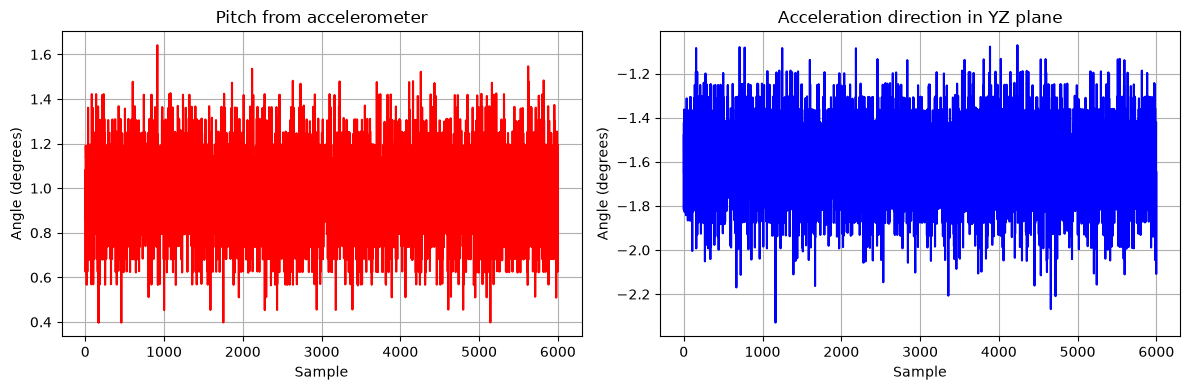

In [5]:
df["pitch_acc"] = np.degrees(np.arctan2(df["ax"], df["az"]))
df["xy_acc_angle"] = np.degrees(np.arctan2(df["ay"], df["az"]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(df["pitch_acc"], color="r")
ax[0].set_title("Pitch from accelerometer")
ax[0].set_xlabel("Sample")
ax[0].set_ylabel("Angle (degrees)")
ax[0].grid(True)

ax[1].plot(df["xy_acc_angle"], color="b")
ax[1].set_title("Acceleration direction in YZ plane")
ax[1].set_xlabel("Sample")
ax[1].set_ylabel("Angle (degrees)")
ax[1].grid(True)

plt.tight_layout()
plt.show()

Drift per minute: 25.3802699550075


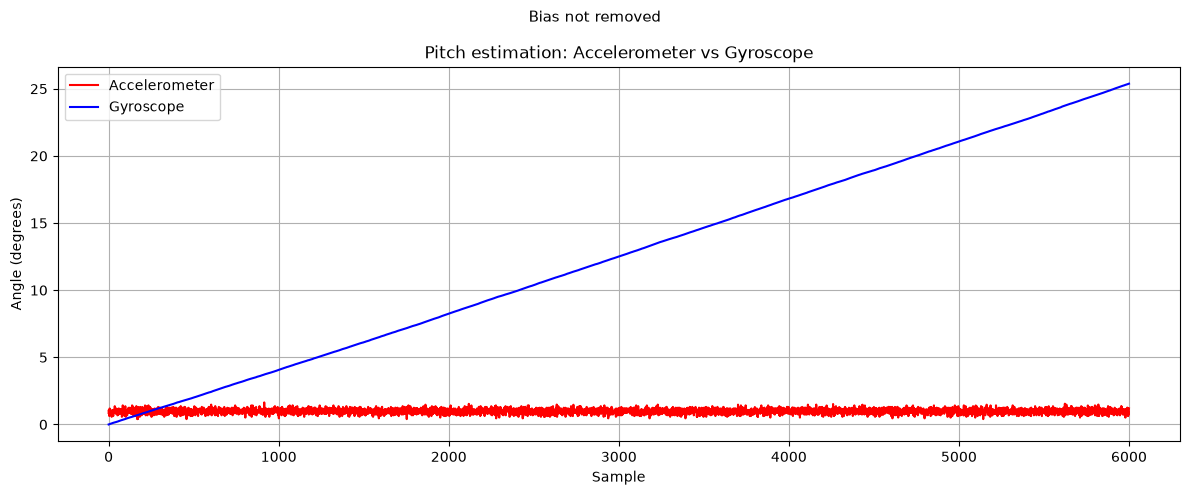

In [6]:
df["angle_gyro_raw"] = (df["gy"] * dt.fillna(0)).cumsum()
drift_per_miunte = df["gy"].mean() * 60 
print(f"Drift per minute: {drift_per_miunte}")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df["pitch_acc"], color="r", label="Accelerometer")
ax.plot(df["angle_gyro_raw"], color="b", label="Gyroscope")

ax.set_xlabel("Sample")
ax.set_ylabel("Angle (degrees)")
ax.set_title("Pitch estimation: Accelerometer vs Gyroscope")
fig.suptitle("Bias not removed", fontsize=11)
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

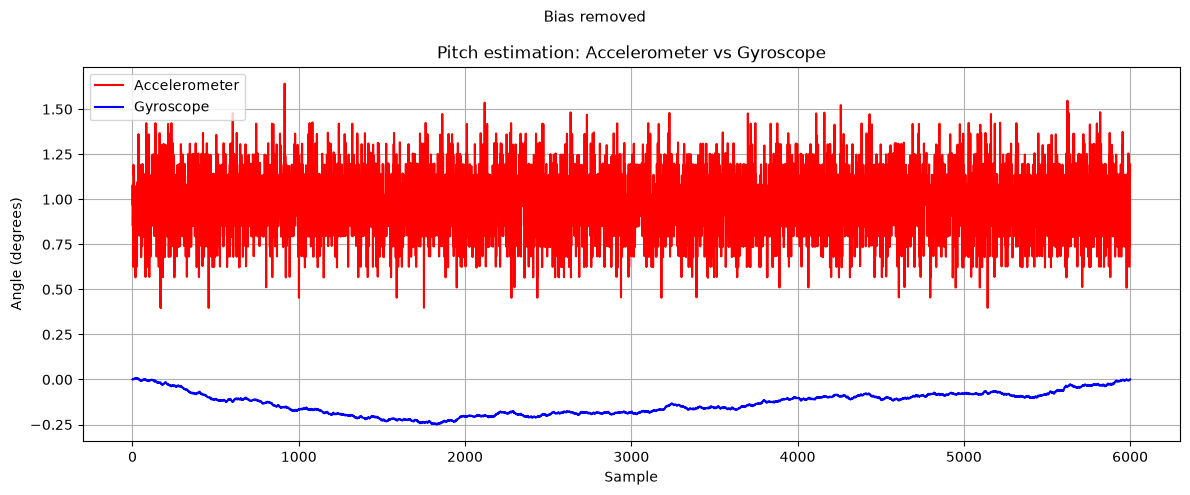

In [7]:
df["angle_gyro_corrected"] = ((df["gy"] - df["gy"].mean()) * dt.fillna(0)).cumsum()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df["pitch_acc"], color="r", label="Accelerometer")
ax.plot(df["angle_gyro_corrected"], color="b", label="Gyroscope")

ax.set_xlabel("Sample")
ax.set_ylabel("Angle (degrees)")
ax.set_title("Pitch estimation: Accelerometer vs Gyroscope")
fig.suptitle("Bias removed", fontsize=11)
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

# Notes
**Bias and noise for each axis:**
| Statistic | ax | ay | az | gx | gy | gz |
|-----------|----------|----------|----------|----------|----------|----------|
| Mean | 0.017287 | -0.028444 | 1.008535 | 0.660590 | 0.423004 | 0.069922 |
| Std | 0.003084 | 0.002988 | 0.002825 | 0.153849 | 0.141333 | 0.148194 |

**Drift per minute without bias correction:**
25.3802699550075
.

**Meaning**
The accelerometer provides a long-term tilt reference but is sensitive to noise, vibration, and linear acceleration. The gyroscope provides angular velocity measurements suitable for short-term orientation tracking, but integration causes drift due to bias and accumulated errors.